Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-realizaciya-gan-na-pytorch

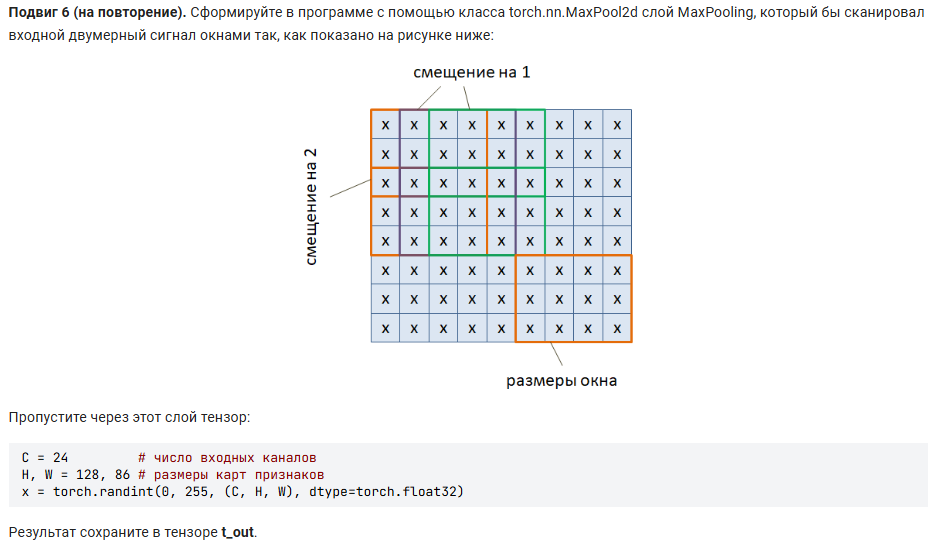

In [12]:
import torch
import torch.nn as nn

C = 24         # число входных каналов
H, W = 128, 86 # размеры карт признаков
x = torch.randint(0, 255, (C, H, W), dtype=torch.float32) # тензор x в программе не менять
layer = torch.nn.MaxPool2d(kernel_size=(3, 4), stride=(2, 1))

t_out = layer(x.unsqueeze(0))
# здесь продолжайте программу
t_out

tensor([[[[243., 228., 228.,  ..., 239., 251., 251.],
          [243., 228., 228.,  ..., 217., 233., 238.],
          [250., 228., 228.,  ..., 233., 233., 238.],
          ...,
          [247., 247., 226.,  ..., 170., 254., 240.],
          [247., 247., 215.,  ..., 229., 254., 230.],
          [231., 231., 216.,  ..., 229., 254., 230.]],

         [[247., 233., 224.,  ..., 252., 225., 192.],
          [247., 224., 224.,  ..., 252., 225., 242.],
          [237., 235., 222.,  ..., 242., 218., 242.],
          ...,
          [237., 237., 243.,  ..., 236., 188., 254.],
          [237., 237., 216.,  ..., 236., 249., 254.],
          [237., 237., 216.,  ..., 236., 249., 254.]],

         [[210., 210., 204.,  ..., 253., 253., 248.],
          [250., 253., 253.,  ..., 253., 253., 248.],
          [250., 253., 253.,  ..., 247., 253., 248.],
          ...,
          [245., 229., 245.,  ..., 249., 249., 241.],
          [245., 229., 243.,  ..., 247., 243., 241.],
          [245., 202., 243.,  ...

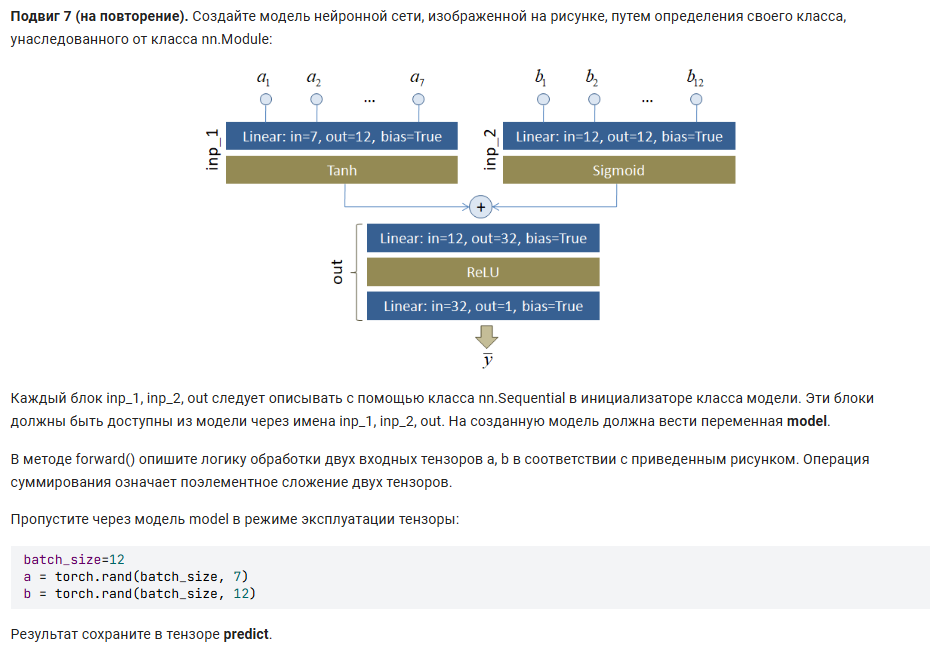

In [13]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.inp_1 = nn.Sequential(nn.Linear(7, 12), nn.Tanh())
        self.inp_2 = nn.Sequential(nn.Linear(12, 12), nn.Sigmoid())
        self.out = nn.Sequential(nn.Linear(12, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x1, x2):
        return self.out(self.inp_1(x1) + self.inp_2(x2))


batch_size=12
a = torch.rand(batch_size, 7) # тензоры a, b в программе не менять
b = torch.rand(batch_size, 12)

model = MyModel()
model.eval()
predict = model(a, b)
predict

tensor([[-1.0028e-02],
        [ 1.3914e-02],
        [ 3.3407e-03],
        [ 1.3390e-02],
        [-5.4537e-03],
        [ 6.9368e-03],
        [ 1.5537e-02],
        [-1.3740e-03],
        [ 8.6991e-03],
        [-1.0561e-02],
        [-3.0950e-05],
        [ 8.6093e-03]], grad_fn=<AddmmBackward0>)

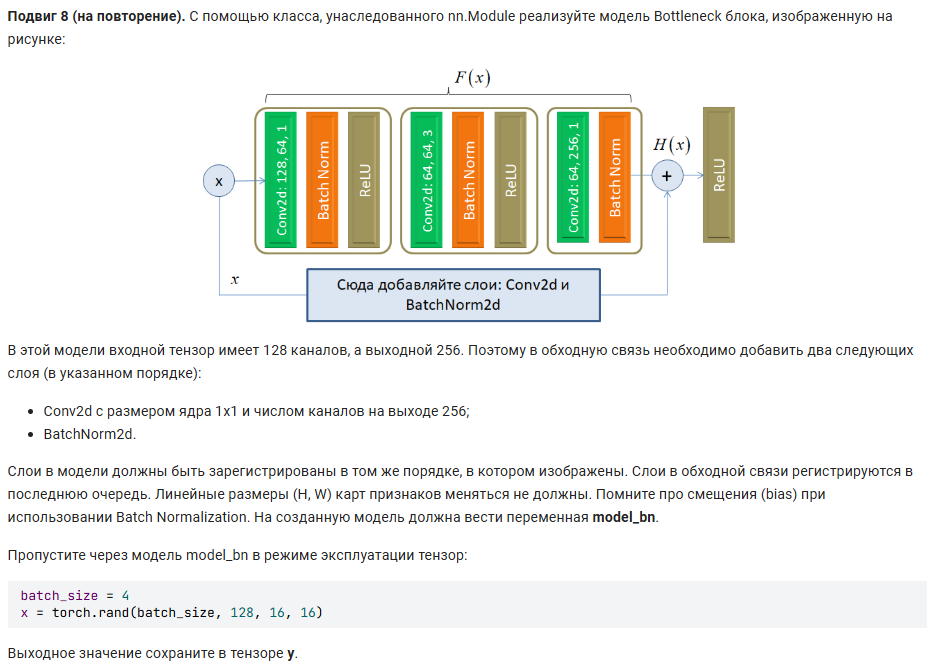

In [51]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class Bottleneck(nn.Module):
    def __init__(self):
        super().__init__()
        self.straight = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=64, kernel_size=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            
            nn.Conv2d(in_channels=64, out_channels=256, kernel_size=1, bias=False),
            nn.BatchNorm2d(256)
        )
        
        self.skip = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=1, bias=False),
            nn.BatchNorm2d(256)
        )
        
    def forward(self, x):
        return torch.relu(self.straight(x) + self.skip(x))
        
        

batch_size = 4
x = torch.rand(batch_size, 128, 16, 16) # тензор x в программе не менять
model_bn = Bottleneck()
model_bn.eval()
y = model_bn(x)
y
# здесь продолжайте программу

tensor([[[[0.0000, 0.0000, 0.1995,  ..., 0.2373, 0.0676, 0.0000],
          [0.0254, 0.0890, 0.0296,  ..., 0.2060, 0.1040, 0.0520],
          [0.0311, 0.1827, 0.0692,  ..., 0.0000, 0.0000, 0.3713],
          ...,
          [0.0000, 0.1576, 0.1443,  ..., 0.1745, 0.1849, 0.0835],
          [0.2655, 0.4806, 0.0000,  ..., 0.1107, 0.1928, 0.0000],
          [0.1037, 0.0000, 0.0000,  ..., 0.2660, 0.0000, 0.1817]],

         [[0.0000, 0.1425, 0.0000,  ..., 0.0975, 0.0000, 0.0000],
          [0.0940, 0.0000, 0.0022,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0082, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0223, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

         [[0.0000, 0.0000, 0.0634,  ..., 0.0182, 0.0000, 0.0876],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0

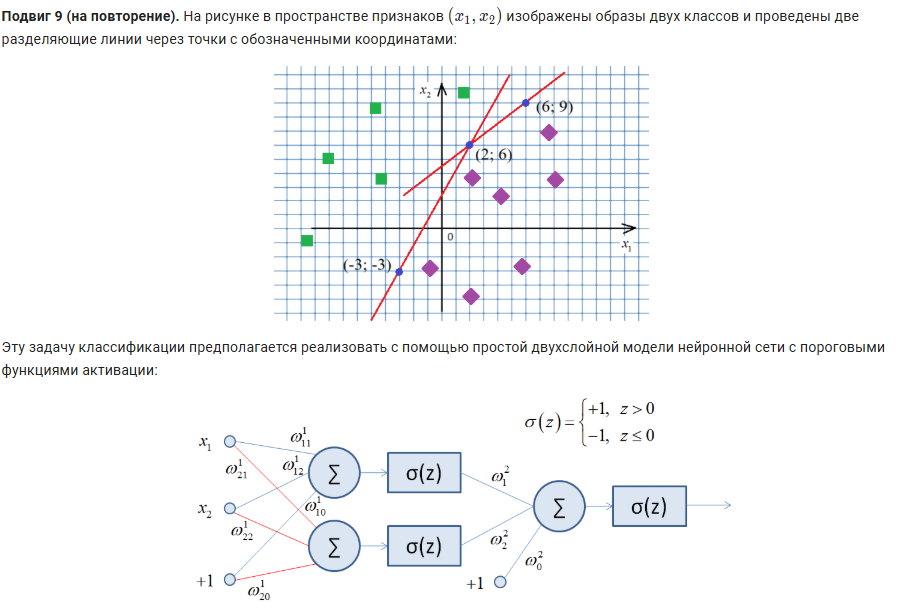

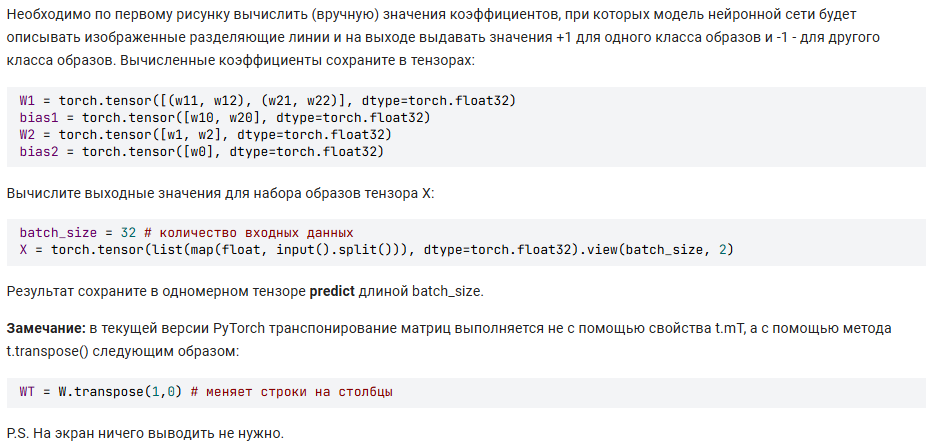

In [64]:
import torch

W1 = torch.tensor([(3, -4), (9, -5)], dtype=torch.float32)
bias1 = torch.tensor([18, 12], dtype=torch.float32)
W2 = torch.tensor([1, 1], dtype=torch.float32)
bias2 = torch.tensor([-1], dtype=torch.float32)

# тензор X в программе не менять
batch_size = 32 # количество входных данных
# X = torch.rand(32, 2, dtype=torch.float32)
X = torch.tensor(list(map(float, input().split())), dtype=torch.float32).view(batch_size, 2)

h = torch.sign(X@W1.transpose(1, 0) + bias1) 
predict = torch.sign(h@W2 + bias2)
predict


tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])